# 06 · Preprocessing and data loaders

Author: Vikas. Group 5, DS and AI Lab.

Turns the clean dataset and its SAM masks into PyTorch loaders for Milestone 3. The split is already fixed by notebook 02, so augmentation touches training photos only and can't leak into validation or test.

**Reads:** `serpentguard-indian-snakes-clean` (03) and `serpentguard-sam-masks` (05). **Saves:** a manifest, class weights and two preview figures. **Time:** a few minutes on CPU.

In [1]:
import warnings
from pathlib import Path

import albumentations as A
import cv2
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from albumentations.pytorch import ToTensorV2
from PIL import Image
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler

warnings.filterwarnings("ignore")

DATA_HANDLE = "puneetbajajiitm/serpentguard-indian-snakes-clean"
MASKS_HANDLE = "puneetbajajiitm/serpentguard-sam-masks"
OUT = Path("/kaggle/working/preprocessed")
OUT.mkdir(parents=True, exist_ok=True)

IMG_SIZE, BATCH_SIZE, SEED = 320, 32, 42
TRAIN_CAP = 1000             # most training photos kept per class
PHOTOGRAPHER_CAP = 50        # most training photos per photographer per class
CLASS_BALANCE_BETA = 0.999   # for class-balanced loss weights
DARK_BELOW, BRIGHT_ABOVE = 60, 200  # mean brightness outside this range gets exposure correction
MASK_MODE = "full"           # full, soft_dim, hard_mask or rgbm_4ch
WHO_RISK_ID = {"not_listed": 0, "2": 1, "1": 2}
WHO_BOOST = {0: 1.0, 1: 1.35, 2: 1.6}
GREY_RGB = (124, 116, 104)   # padding, and the background in the masked modes
BACKGROUND_KEEP = 0.20       # how much background soft_dim keeps
CROP_PADDING = 0.06          # margin around the mask in the masked modes
MIN_MASK_SHARE = 0.015       # a mask smaller than this share of the photo is not used
MIN_PART_SHARE = 0.008       # smallest separate part of a mask to keep, as a share of the photo
MIN_PART_OF_LARGEST = 0.12   # and as a share of the largest part
SHAREABLE = ["cc0", "cc-by"]  # the only licences the saved previews show
ID_TYPES = {"obs_id": str, "photo_id": str, "observer_id": str}

## 1. Join photos, class ids and masks

Class ids come from `classes.csv`, because `val/` and `test/` lack some species folders. A mask is usable when it
exists and is not flagged; validation and test photos have none, on purpose.

In [2]:
data_root = Path(kagglehub.dataset_download(DATA_HANDLE))
masks_root = Path(kagglehub.dataset_download(MASKS_HANDLE))
classes = pd.read_csv(data_root / "classes.csv")
df = pd.read_csv(data_root / "metadata.csv", dtype=ID_TYPES, low_memory=False)
df = df[df["split"] != "unknown_pool"].merge(classes[["species", "class_id"]], on="species", validate="many_to_one")

for level in ("genus", "family"):
    ids = {name: i for i, name in enumerate(sorted(classes[level].unique()))}
    df[f"{level}_id"] = df[level].map(ids)
df["who_risk_id"] = df["who_category"].astype(str).map(WHO_RISK_ID).astype(int)
df["image_file"] = [str(data_root / "data" / path) for path in df["path"]]

stats = pd.read_csv(masks_root / "mask_stats.csv", usecols=["path", "mask_path", "flagged"])
df = df.merge(stats, on="path", how="left", validate="one_to_one")
usable = df["mask_path"].notna() & df["flagged"].eq(False)
df["mask_file"] = ""
df.loc[usable, "mask_file"] = [str(masks_root / "masks" / path) for path in df.loc[usable, "mask_path"]]

print(f"{len(df):,} photos in {len(classes)} classes, {df['genus_id'].nunique()} genera, {df['family_id'].nunique()} families")
print("Photos by split:", df["split"].value_counts().to_dict())
print(f"Usable masks: {usable.sum():,} of {df['split'].eq('train').sum():,} training photos")

120,751 photos in 184 classes, 69 genera, 13 families
Photos by split: {'train': 85067, 'val': 17151, 'test_extra': 13389, 'test': 5144}
Usable masks: 63,438 of 85,067 training photos


## 2. Exposure, masks, cropping and resizing

- **Exposure:** very dark or overexposed photos get contrast correction (CLAHE on lightness only), in every split. We keep night photos instead of dropping them, because many species are seen at night.
- **Masks:** closing fills small gaps, and keeping the large parts removes specks but keeps separate coils.
- **Input modes:** in `full`, the default, the whole photo goes in and the mask is only the segmentation target. `soft_dim`, `hard_mask` and `rgbm_4ch` crop to the mask (+6%) and dim, remove or add it as a channel. Milestone 3 compares them, using the segmentation model's own mask at test time, because SAM won't run on the phone.
- **Letterbox:** keeps body shape, because stretching would make a slender vine snake look stout.

In [3]:
CLOSE_KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))


CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))


def load_rgb(path):
    with Image.open(path) as image:
        rgb = np.asarray(image.convert("RGB"), dtype=np.uint8)
    return fix_exposure(rgb)


def fix_exposure(rgb):
    if DARK_BELOW <= rgb.mean() <= BRIGHT_ABOVE:
        return rgb
    lightness, a, b = cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))
    return cv2.cvtColor(cv2.merge([CLAHE.apply(lightness), a, b]), cv2.COLOR_LAB2RGB)


def load_mask(path, shape):
    """The cleaned mask, or None when the photo has no usable mask."""
    if not path:
        return None
    with Image.open(path) as image:
        mask = (np.asarray(image.convert("L")) > 127).astype(np.uint8)
    if mask.shape != shape:
        raise ValueError(f"mask {mask.shape} does not match photo {shape}: {path}")
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, CLOSE_KERNEL)
    parts, labels, part_stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    areas = part_stats[1:, cv2.CC_STAT_AREA]
    if parts <= 1 or areas.max() < MIN_MASK_SHARE * mask.size:
        return None
    keep = 1 + np.flatnonzero(areas >= max(MIN_PART_OF_LARGEST * areas.max(), MIN_PART_SHARE * mask.size))
    return np.isin(labels, keep).astype(np.uint8)


def prepare(rgb, mask, mode=MASK_MODE):
    """Applies the input mode and letterboxes the photo and mask to IMG_SIZE."""
    target = np.zeros(rgb.shape[:2], np.uint8) if mask is None else mask
    if mode != "full" and mask is not None:
        if mode != "rgbm_4ch":
            keep = 0.0 if mode == "hard_mask" else BACKGROUND_KEEP
            weight = keep + (1 - keep) * cv2.GaussianBlur(mask.astype(np.float32), (5, 5), 0)[..., None]
            rgb = (rgb * weight + np.array(GREY_RGB) * (1 - weight)).astype(np.uint8)
        ys, xs = np.nonzero(mask)
        pad_x, pad_y = int(np.ptp(xs) * CROP_PADDING), int(np.ptp(ys) * CROP_PADDING)
        window = (slice(max(0, ys.min() - pad_y), ys.max() + pad_y + 1), slice(max(0, xs.min() - pad_x), xs.max() + pad_x + 1))
        rgb, target = rgb[window], target[window]

    height, width = rgb.shape[:2]
    scale = IMG_SIZE / max(height, width)
    size = (max(1, round(width * scale)), max(1, round(height * scale)))
    rgb = cv2.resize(rgb, size, interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR)
    target = cv2.resize(target, size, interpolation=cv2.INTER_NEAREST)
    top, left = (IMG_SIZE - size[1]) // 2, (IMG_SIZE - size[0]) // 2
    canvas = np.full((IMG_SIZE, IMG_SIZE, 3), GREY_RGB, dtype=np.uint8)
    canvas_mask = np.zeros((IMG_SIZE, IMG_SIZE), np.uint8)
    canvas[top:top + size[1], left:left + size[0]] = rgb
    canvas_mask[top:top + size[1], left:left + size[0]] = target
    return canvas, canvas_mask

## 3. Augment

Training photos only, as they load, so nothing is stored and every epoch differs. Flips, zoom, rotation and shift move the photo and mask together. Tier 2 classes have fewer photos, so they get stronger settings. Hue stays within about 4% because colour bands identify some species.

Some rare classes come from one or two photographers, so the model could learn a camera instead of a snake. JPEG compression, downscaling, blur and white-balance shifts make camera style less useful. Validation and test photos are only normalised.

In [4]:
TO_TENSOR = [A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)), ToTensorV2()]
CAMERA_STYLE = [
    A.ImageCompression(quality_range=(40, 95), p=0.3),
    A.Downscale(scale_range=(0.5, 0.9), p=0.2),
    A.GaussianBlur(blur_limit=(3, 5), p=0.15),
    A.RGBShift(r_shift_limit=12, g_shift_limit=12, b_shift_limit=12, p=0.3),
]
AUGMENT = {
    "tier1": A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.2),
        A.Affine(scale=(0.88, 1.12), rotate=(-25, 25), translate_percent=(-0.05, 0.05), border_mode=cv2.BORDER_CONSTANT, p=0.6),
        A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.04, p=0.5),
        A.CoarseDropout(num_holes_range=(1, 4), hole_height_range=(16, 36), hole_width_range=(16, 36), p=0.35),
        *CAMERA_STYLE,
        *TO_TENSOR,
    ]),
    "tier2": A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.35),
        A.Affine(scale=(0.80, 1.20), rotate=(-45, 45), translate_percent=(-0.08, 0.08), shear=(-10, 10), border_mode=cv2.BORDER_CONSTANT, p=0.8),
        A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.7),
        A.HueSaturationValue(hue_shift_limit=8, sat_shift_limit=25, val_shift_limit=25, p=0.5),
        A.MotionBlur(blur_limit=(3, 7), p=0.25),
        A.CoarseDropout(num_holes_range=(2, 6), hole_height_range=(20, 44), hole_width_range=(20, 44), p=0.5),
        *CAMERA_STYLE,
        *TO_TENSOR,
    ]),
    "eval": A.Compose(TO_TENSOR),
}


class SnakeDataset(Dataset):
    """Returns the image, the mask, whether that mask is real, and the four class targets."""

    def __init__(self, frame, train=False, mode=MASK_MODE):
        self.frame, self.train, self.mode = frame.reset_index(drop=True), train, mode

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        rgb = load_rgb(row["image_file"])
        mask = load_mask(row["mask_file"], rgb.shape[:2])
        image, target = prepare(rgb, mask, self.mode)
        sample = AUGMENT[row["tier"] if self.train else "eval"](image=image, mask=target)
        target = sample["mask"].unsqueeze(0).float()
        image = torch.cat([sample["image"], target]) if self.mode == "rgbm_4ch" else sample["image"]
        return {"image": image, "mask": target, "mask_valid": mask is not None,
                **{name: int(row[name]) for name in ("class_id", "genus_id", "family_id", "who_risk_id")}}

## 4. Balance

The classes are heavily imbalanced, and loss weighting alone isn't enough, so three steps work together:

1. **Caps:** up to 50 photos per photographer per class and 1,000 per class, taking photographers in turn, so nobody fills a class.
2. **Sampler:** each photo is drawn with weight 1/√(class size), boosted for WHO-listed species. Full 1/N weighting would repeat the smallest classes too often.
3. **Loss weights:** class-balanced weights are saved for the Milestone 3 loss.

`mask_valid` is False for a photo with no usable mask, and its target is empty, so the segmentation loss must skip it.

In [5]:
def cap_train(train):
    shuffled = train.sample(frac=1, random_state=SEED)
    turn = shuffled.groupby(["species", "observer_id"]).cumcount()
    kept = shuffled.assign(turn=turn)[turn < PHOTOGRAPHER_CAP].sort_values("turn", kind="stable")
    return kept.groupby("species").head(TRAIN_CAP).drop(columns="turn")


def effective_classes(sizes):
    share = np.asarray(sizes) / np.sum(sizes)
    return 1 / np.sum(share ** 2)


all_train = df[df["split"] == "train"]
train_df = cap_train(all_train).reset_index(drop=True)
class_size = train_df.groupby("class_id")["class_id"].transform("size")
weights = (1 / np.sqrt(class_size) * train_df["who_risk_id"].map(WHO_BOOST)).to_numpy()
sampler = WeightedRandomSampler(torch.as_tensor(weights, dtype=torch.double), len(train_df), replacement=True, generator=torch.Generator().manual_seed(SEED))

frames = {"train": train_df, **{split: df[df["split"] == split] for split in ("val", "test", "test_extra")}}
loaders = {split: DataLoader(SnakeDataset(frame, train=split == "train"), BATCH_SIZE, sampler=sampler if split == "train" else None, num_workers=2)
           for split, frame in frames.items()}

stages = {"all training photos": all_train["class_id"], "after the caps": train_df["class_id"], "one epoch from the sampler": train_df["class_id"].iloc[list(sampler)]}
for stage, ids in stages.items():
    sizes = ids.value_counts()
    print(f"{stage:<28} {len(ids):>7,} photos, largest / smallest class {sizes.max() / sizes.min():6.1f}, effective classes {effective_classes(sizes):5.1f}")
print({split: len(loader) for split, loader in loaders.items()}, "batches")

class_counts = train_df.groupby(["class_id", "species"]).size().rename("train_photos").reset_index()
effective = (1 - CLASS_BALANCE_BETA ** class_counts["train_photos"]) / (1 - CLASS_BALANCE_BETA)
class_counts["loss_weight"] = (1 / effective) * len(class_counts) / (1 / effective).sum()
class_counts.to_csv(OUT / "class_weights.csv", index=False)
print(f"Loss weights run from {class_counts['loss_weight'].min():.2f} to {class_counts['loss_weight'].max():.2f}")

all training photos           85,067 photos, largest / smallest class  876.0, effective classes  31.9
after the caps                52,308 photos, largest / smallest class  100.0, effective classes  76.4
one epoch from the sampler    52,308 photos, largest / smallest class   15.6, effective classes 118.6
{'train': 1635, 'val': 536, 'test': 161, 'test_extra': 419} batches
Loss weights run from 0.10 to 6.04


## 5. Check a real batch

In [6]:
batch, val_batch = next(iter(loaders["train"])), next(iter(loaders["val"]))
for name, value in batch.items():
    print(f"{name:<12} {tuple(value.shape)} {value.dtype}")
assert batch["image"].shape == (BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE) and batch["image"].flatten(1).std(1).min() > 0
assert batch["mask"][~batch["mask_valid"]].sum() == 0
assert not val_batch["mask_valid"].any()
print(f"Real masks in this training batch: {int(batch['mask_valid'].sum())} of {BATCH_SIZE}; in the validation batch: {int(val_batch['mask_valid'].sum())}")

manifest = df[["path", "split", "species", "tier", "class_id", "genus_id", "family_id", "who_risk_id", "mask_path"]].copy()
manifest["in_capped_train"] = manifest["path"].isin(train_df["path"])
manifest.to_csv(OUT / "preprocessed_manifest.csv", index=False)
print(f"Manifest: {len(manifest):,} rows")

image        (32, 3, 320, 320) torch.float32
mask         (32, 1, 320, 320) torch.float32
mask_valid   (32,) torch.bool
class_id     (32,) torch.int64
genus_id     (32,) torch.int64
family_id    (32,) torch.int64
who_risk_id  (32,) torch.int64
Real masks in this training batch: 25 of 32; in the validation batch: 0
Manifest: 120,751 rows


## 6. Preview

Saved notebooks are public, so these figures use only CC0 and CC BY photos, with credits printed below them.

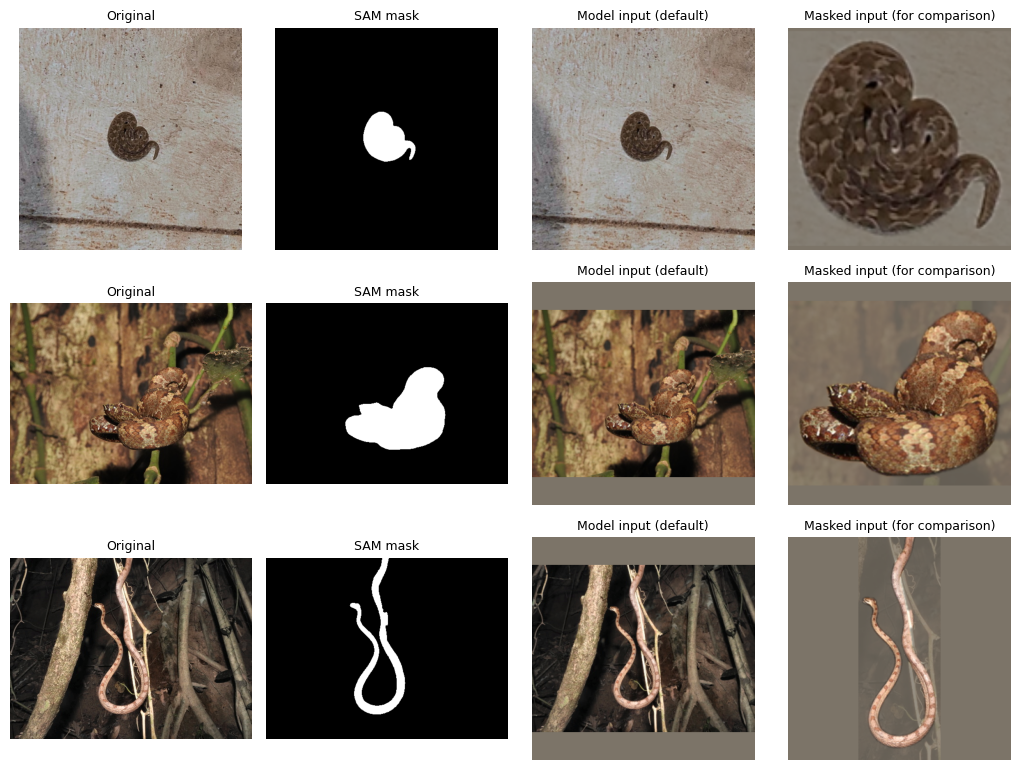

                     species license                                attribution
             Echis carinatus   cc-by (c) Giri RAO, some rights reserved (CC BY)
Craspedocephalus malabaricus   cc-by (c) Hopeland, some rights reserved (CC BY)
              Boiga nuchalis   cc-by (c) Hopeland, some rights reserved (CC BY)


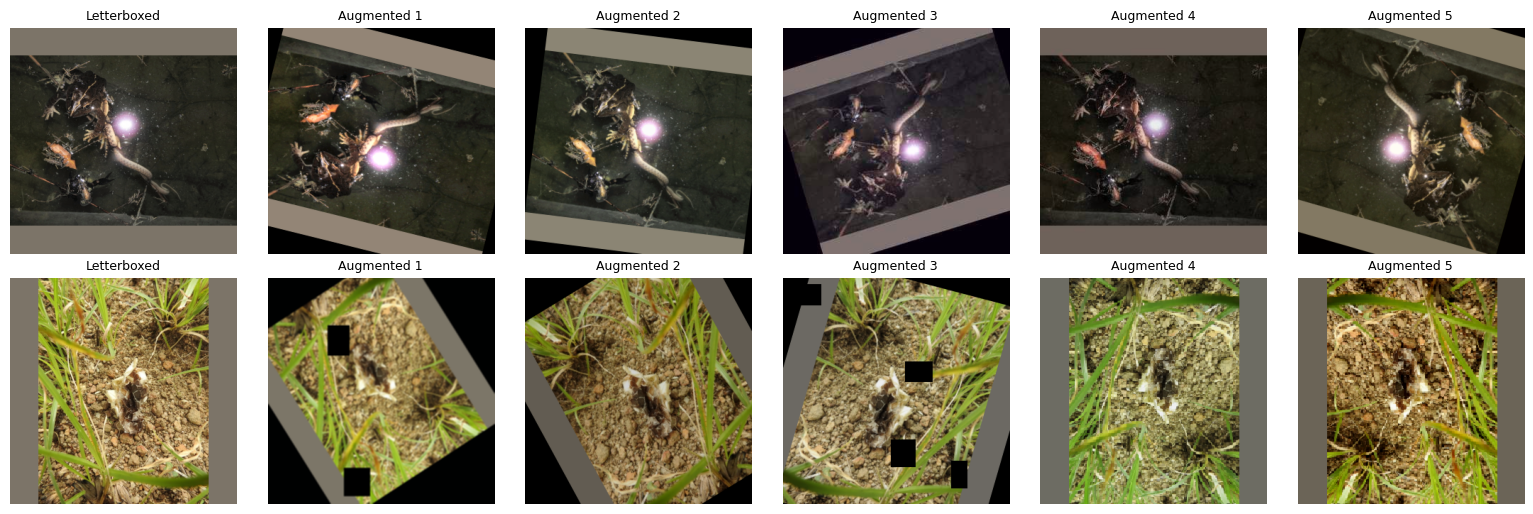

             species license                                attribution
     Fowlea piscator   cc-by (c) Hopeland, some rights reserved (CC BY)
Ophiophagus kaalinga   cc-by (c) Hopeland, some rights reserved (CC BY)


In [7]:
def show_grid(rows, titles, name):
    figure, axes = plt.subplots(len(rows), len(titles), figsize=(2.6 * len(titles), 2.6 * len(rows)), squeeze=False)
    for row_axes, images in zip(axes, rows):
        for axis, image, title in zip(row_axes, images, titles):
            axis.imshow(image, cmap="gray" if image.ndim == 2 else None)
            axis.set_title(title, fontsize=9)
            axis.axis("off")
    figure.tight_layout()
    figure.savefig(OUT / name, dpi=110, bbox_inches="tight")
    plt.show()


def undo_normalise(tensor):
    mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
    return ((tensor.permute(1, 2, 0).numpy() * std + mean).clip(0, 1) * 255).astype(np.uint8)


def credits(frame):
    print(frame[["species", "license", "attribution"]].to_string(index=False))


pool = df[(df["split"] == "train") & usable & df["license"].isin(SHAREABLE)]
picked = pool.groupby("who_risk_id").sample(1, random_state=7).sort_values("who_risk_id", ascending=False)
rows = []
for row in picked.itertuples():
    rgb = load_rgb(row.image_file)
    mask = load_mask(row.mask_file, rgb.shape[:2])
    rows.append([rgb, mask * 255, prepare(rgb, mask, "full")[0], prepare(rgb, mask, "soft_dim")[0]])
show_grid(rows, ["Original", "SAM mask", "Model input (default)", "Masked input (for comparison)"], "preprocessing_preview.png")
credits(picked)

examples = pd.concat([pool[pool["tier"] == tier].sample(1, random_state=11) for tier in ("tier1", "tier2")])
rows = []
for row in examples.itertuples():
    image, target = prepare(load_rgb(row.image_file), load_mask(row.mask_file, (row.height, row.width)))
    rows.append([image] + [undo_normalise(AUGMENT[row.tier](image=image, mask=target)["image"]) for _ in range(5)])
show_grid(rows, ["Letterboxed", *[f"Augmented {i}" for i in range(1, 6)]], "augmentation_preview.png")
credits(examples)